In [1]:
import pandas as pd

sample_data = pd.DataFrame({
    "product_name": [
        "Noise Buds VS104 Earbuds",
        "Noise Buds VS104 Earbuds",
        "Noise Buds VS104 Earbuds",
        "boAt Rockerz 450 Headphones",
        "boAt Rockerz 450 Headphones",
        "SanDisk 64GB Ultra USB Flash Drive",
        "SanDisk 64GB Ultra USB Flash Drive",
        "Pigeon Polypropylene Mini Chopper",
    ],
    "product_price": [
        "₹1,099",
        "₹1,099",
        "1,099",
        "Rs. 1,499",
        "1499",
        "₹549",
        "₹549",
        "₹299",
    ],
    "Rate": ["4.2", "5", "3.8", "4.5", "4.0", "4.7", "4.3", "3.2"],
    "Summary": [
        "Good battery life and decent sound quality",
        "Awesome value for money, nice bass",
        "Average mic quality in noisy places",
        "Super comfortable and good sound",
        "Nice build quality worth the price",
        "Fast transfer speed, reliable product",
        "Good storage for daily use",
        "Blade works okay but lid feels cheap",
    ],
})

sample_data.to_csv("Dataset-SA.csv", index=False)
print("Created sample Dataset-SA.csv with", len(sample_data), "rows.")

Created sample Dataset-SA.csv with 8 rows.


In [2]:
pip install pandas matplotlib wordcloud

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from wordcloud import STOPWORDS, WordCloud

# 1. Load the dataset (update the path to your downloaded Kaggle CSV file)
file_path = r"C:\Users\SARAL\Desktop\FSK-Training"
df = pd.read_csv(file_path)

# Optional: inspect available columns and sample rows
print("Original columns:", df.columns.tolist())
print(df.head(3))

# Normalize column names to lowercase with underscores for consistent handling
df.columns = [col.strip().lower().replace(" ", "_") for col in df.columns]

# Map common Flipkart dataset column aliases to standard names
column_aliases = {
    "product_name": ["product_name", "product", "product_title", "item_name"],
    "rating": ["rating", "rate", "product_rating", "stars"],
    "price": ["price", "product_price", "selling_price", "mrp"],
    "summary": ["summary", "review_summary", "review", "comment", "feedback"],
}

resolved_cols = {}
for target, candidates in column_aliases.items():
  for cand in candidates:
    if cand in df.columns:
      resolved_cols[target] = cand
      break

product_col = resolved_cols["product_name"]
rating_col = resolved_cols["rating"]
price_col = resolved_cols["price"]
summary_col = resolved_cols["summary"]

# Clean 'price': strip currency symbols (₹, $), commas, and whitespace, then convert to float
df["clean_price"] = (
    df[price_col]
    .astype(str)
    .str.replace(r"[₹$,\s]", "", regex=True)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)
df["clean_price"] = pd.to_numeric(df["clean_price"], errors="coerce")

# Clean 'rating': extract numeric rating (e.g., "4.5" or "4 out of 5") and filter to valid 1-5 range
df["clean_rating"] = (
    df[rating_col]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)
df["clean_rating"] = pd.to_numeric(df["clean_rating"], errors="coerce")

# Keep valid ratings (typically between 1 and 5) and positive prices
df.loc[(df["clean_rating"] < 1) | (df["clean_rating"] > 5), "clean_rating"] = pd.NA
df.loc[df["clean_price"] <= 0, "clean_price"] = pd.NA

# Clean product names by trimming extra whitespace
df["clean_product_name"] = df[product_col].astype(str).str.strip()
df.loc[df["clean_product_name"].isin(["", "nan", "None"]), "clean_product_name"] = pd.NA

# Drop rows where product name, rating, or price could not be parsed cleanly
clean_df = df.dropna(subset=["clean_product_name", "clean_rating", "clean_price"]).copy()

print(f"\nRows before cleaning: {len(df)} | Rows after cleaning: {len(clean_df)}")
print(clean_df[["clean_product_name", "clean_rating", "clean_price"]].describe())

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\SARAL\\Desktop\\FSK-Training'

In [2]:
from pathlib import Path
import pandas as pd

folder = Path(r"C:\Users\SARAL\Desktop\FSK-Training")
csv_files = list(folder.glob("*.csv"))

if not csv_files:
  raise FileNotFoundError(f"No .csv file found in {folder}")

file_path = csv_files[0]
print("Loading:", file_path)
df = pd.read_csv(file_path)

Loading: C:\Users\SARAL\Desktop\FSK-Training\Dataset-SA.csv


In [3]:
# 2. Group by product name and calculate mean rating and mean price
items = (
    clean_df.groupby("clean_product_name", as_index=False)
    .agg(
        mean_rating=("clean_rating", "mean"),
        mean_price=("clean_price", "mean"),
        review_count=("clean_rating", "count"),
    )
    .rename(columns={"clean_product_name": "product_name"})
)

# Round numeric metrics for clean presentation
items["mean_rating"] = items["mean_rating"].round(2)
items["mean_price"] = items["mean_price"].round(2)

# Sort by highest review count or highest mean rating
items = items.sort_values(by="review_count", ascending=False).reset_index(drop=True)

print("\nSummary DataFrame 'items' (Top 10 by review count):")
print(items.head(10))

NameError: name 'clean_df' is not defined

In [4]:
# --- Run Step 1 first (using your working CSV path) ---
df.columns = [col.strip().lower().replace(" ", "_") for col in df.columns]

column_aliases = {
    "product_name": ["product_name", "product", "product_title", "item_name"],
    "rating": ["rating", "rate", "product_rating", "stars"],
    "price": ["price", "product_price", "selling_price", "mrp"],
    "summary": ["summary", "review_summary", "review", "comment", "feedback"],
}

resolved_cols = {}
for target, candidates in column_aliases.items():
  for cand in candidates:
    if cand in df.columns:
      resolved_cols[target] = cand
      break

product_col = resolved_cols["product_name"]
rating_col = resolved_cols["rating"]
price_col = resolved_cols["price"]
summary_col = resolved_cols["summary"]

df["clean_price"] = (
    df[price_col]
    .astype(str)
    .str.replace(r"[₹$,\s]", "", regex=True)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)
df["clean_price"] = pd.to_numeric(df["clean_price"], errors="coerce")

df["clean_rating"] = (
    df[rating_col]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)
df["clean_rating"] = pd.to_numeric(df["clean_rating"], errors="coerce")

df.loc[(df["clean_rating"] < 1) | (df["clean_rating"] > 5), "clean_rating"] = pd.NA
df.loc[df["clean_price"] <= 0, "clean_price"] = pd.NA

df["clean_product_name"] = df[product_col].astype(str).str.strip()
df.loc[df["clean_product_name"].isin(["", "nan", "None"]), "clean_product_name"] = pd.NA

# This line defines `clean_df`
clean_df = df.dropna(subset=["clean_product_name", "clean_rating", "clean_price"]).copy()
print("clean_df created with rows:", len(clean_df))

clean_df created with rows: 205051


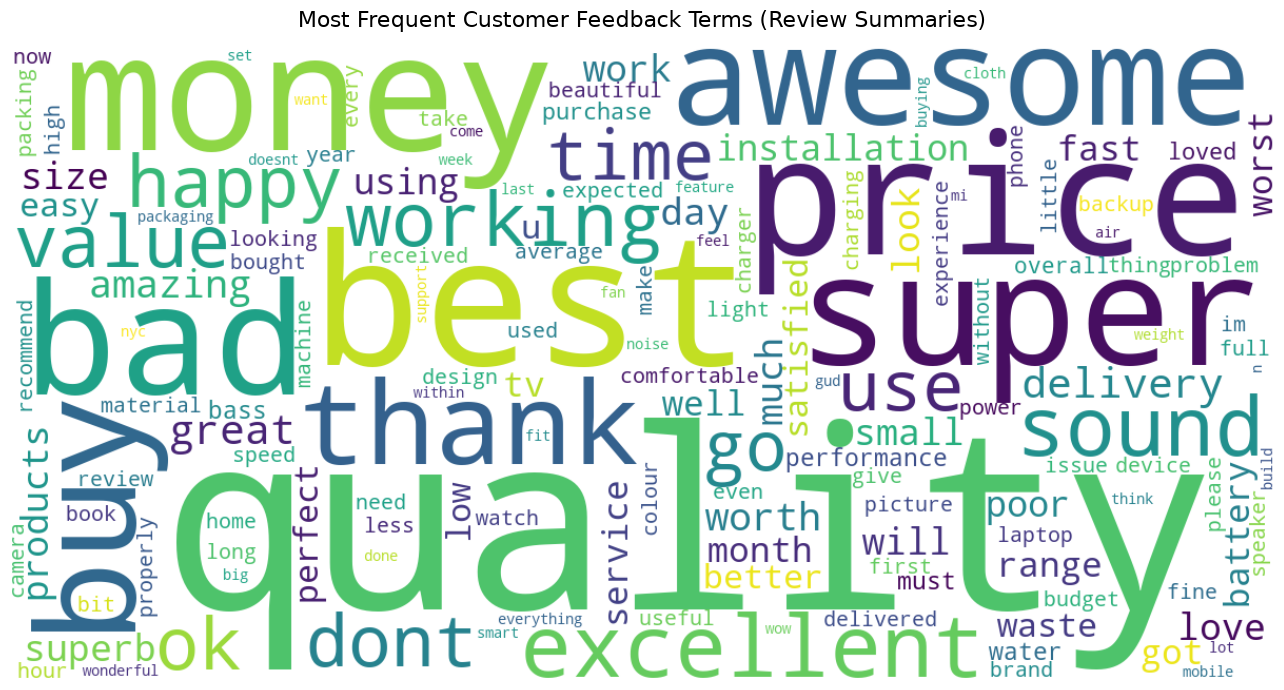

In [5]:
import matplotlib.pyplot as plt
from wordcloud import STOPWORDS, WordCloud

# Gather non-empty review summaries
summaries = df[summary_col].dropna().astype(str).str.strip()
summaries = summaries[summaries != ""]
text_corpus = " ".join(summaries.tolist())

# Filter out standard stopwords plus common filler words
custom_stopwords = set(STOPWORDS).union({
    "product",
    "flipkart",
    "good",
    "nice",
    "very",
    "one",
    "really",
    "item",
})

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=custom_stopwords,
    max_words=150,
    collocations=False,
    colormap="viridis",
).generate(text_corpus)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Most Frequent Customer Feedback Terms (Review Summaries)",
    fontsize=16,
    pad=15,
)
plt.tight_layout()
plt.show()